# Spanish power prices vs renewables

Analysis of the Spanish day-ahead electricity market against the peninsular generation mix.

**Questions**
1. How does the day-ahead price move with the renewables share of demand?
2. When do zero and negative prices happen (month × hour)?
3. Solar cannibalisation: how far below the average price does solar's output clear, and is it getting worse?

**Data** (no API token needed; see README for details and licences)
- Prices: OMIE day-ahead marginal price for Spain (`marginalpdbc` daily files). Since 1 Oct 2025 the market clears in 15-minute periods; they are averaged to clock hours here.
- Generation and demand: REE real-time peninsular feed (5-minute resolution, averaged to hours), calibrated so each day's totals match REE's official daily figures from the REData API. The real-time feed changed method on 11 Dec 2025 (solar PV jumped ~23% overnight versus REData), and calibration removes that break.
- *Renewables share* = (wind + solar PV + solar thermal + hydro output) / peninsular demand, per hour. It can exceed 100% when Spain exports or pumps.

Refresh the data with `python scripts/refresh.py`; this notebook reads `data/processed/hourly.parquet`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import plotly.io as pio

from spain_power import cache, charts, findings, transform as t

pio.renderers.default = "png"  # static images so the notebook renders on GitHub
pd.set_option("display.float_format", "{:,.2f}".format)

df = cache.load_hourly(ROOT / "data" / "processed" / "hourly.parquet")
h = findings.headline(df)
print(f"{len(df):,} hours from {df['date'].min()} to {df['date'].max()}")
print(f"calibrated to REData daily totals: {df['calibrated'].mean():.1%} of hours")
df[["ts", "price_es", "demand", "solar", "wind", "renewables_share"]].tail()

17,735 hours from 2024-10-01 to 2026-10-09
calibrated to REData daily totals: 99.9% of hours


,ts,price_es,demand,solar,wind,renewables_share
17730,2026-10-09 18:00:00+02:00,113.74,"29,923.67","17,369.67","5,735.58",0.77
17731,2026-10-09 19:00:00+02:00,192.32,"28,756.58","3,797.08","5,724.08",0.49
17732,2026-10-09 20:00:00+02:00,198.34,"29,383.67",576.00,"6,235.50",0.43
17733,2026-10-09 21:00:00+02:00,192.66,"28,805.42",471.58,"6,714.42",0.44
17734,2026-10-09 22:00:00+02:00,188.31,"27,168.40",469.80,"6,843.80",0.46


## 0. Two comparable 12-month windows
October–September windows so both cover a full seasonal cycle.

In [2]:
w = findings.window_table(df)
w.style.format("{:,.3f}")

,Oct 2024–Sep 2025,Oct 2025–Sep 2026
hours,"8,760.000","8,760.000"
avg_price,71.270,73.295
zero_or_negative_hours,775.000,944.000
negative_hours,540.000,768.000
pct_zero_or_negative,0.088,0.108
renewables_share,0.596,0.611
solar_share,0.215,0.249
solar_capture,40.050,38.919
solar_capture_rate,0.562,0.531
midday_11_16,38.941,25.252


## 1. Price vs renewables share

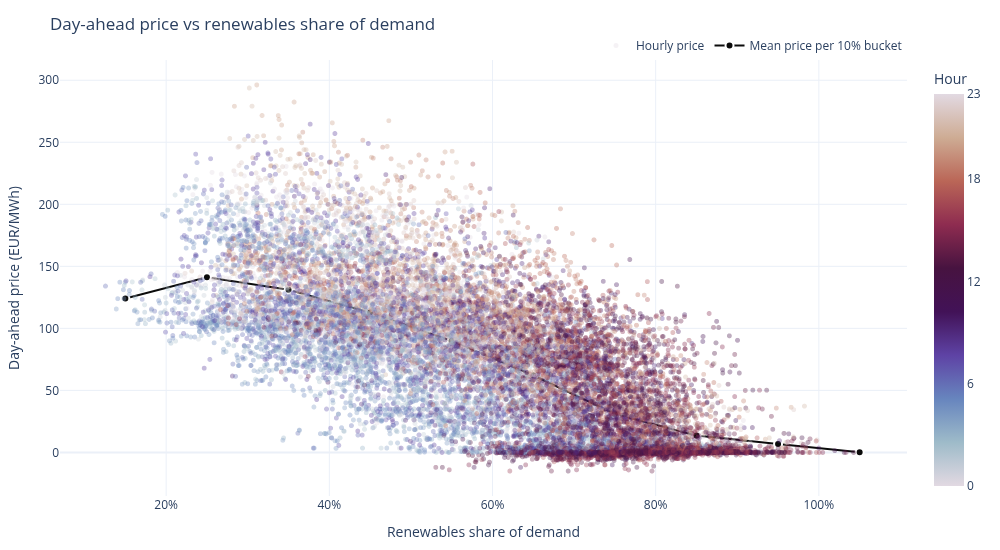

In [3]:
charts.fig_price_vs_renewables(df).show(width=1000, height=550)

In [4]:
buckets = t.share_buckets(df.dropna(subset=["renewables_share"]))
print(f"Pearson correlation, hourly price vs renewables share: {h['corr_price_renewables']:.2f}")
print(f"Mean price when renewables < 40% of demand: {h['price_share_lt40']:.1f} EUR/MWh")
print(f"Mean price when renewables >= 80% of demand: {h['price_share_ge80']:.1f} EUR/MWh")
buckets

Pearson correlation, hourly price vs renewables share: -0.72
Mean price when renewables < 40% of demand: 133.6 EUR/MWh
Mean price when renewables >= 80% of demand: 12.9 EUR/MWh


,mean,median,count
10%-20%,124.05,121.44,50
20%-30%,141.26,132.96,717
30%-40%,131.12,122.87,1992
40%-50%,112.75,109.00,2774
50%-60%,89.98,92.07,2920
60%-70%,62.05,64.96,3426
70%-80%,31.06,18.63,3801
80%-90%,13.58,3.00,1835
90%-100%,6.74,0.80,202
100%-110%,0.25,0.00,6


Prices fall steadily as renewables cover more of demand, and the median collapses to around zero once the share passes ~80%. The fall is not linear: below ~40% gas (combined cycle) sets the price, while above ~70% the price is set by renewables bidding near zero.

The hours from 12:00 on 28 Apr 2025 (the Iberian blackout) are kept in the price series but excluded from share calculations, because measured demand collapsed to near zero.

## 2. Zero and negative price hours

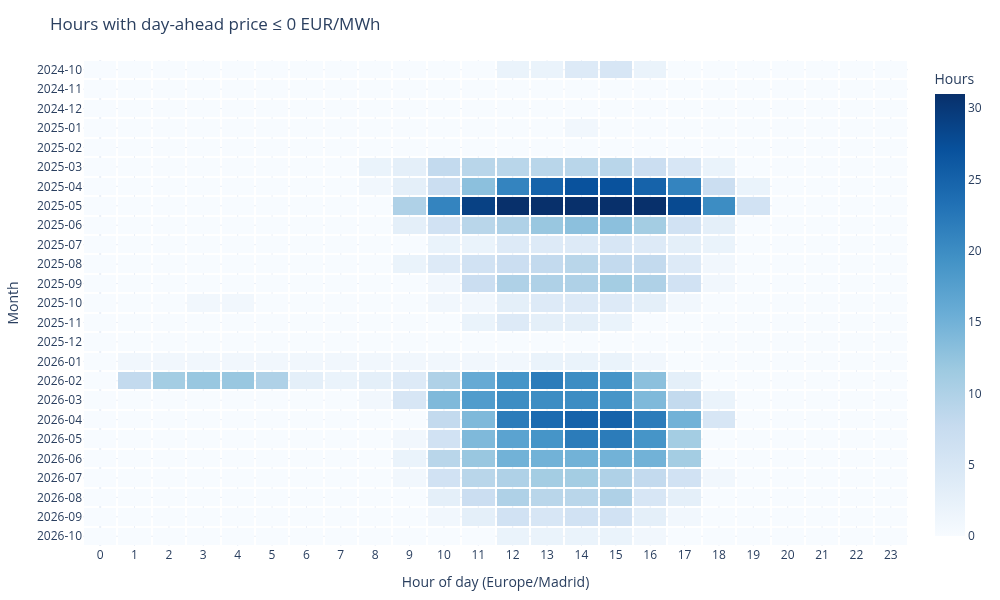

In [5]:
charts.fig_negative_heatmap(df).show(width=1000, height=600)

In [6]:
z = df[df["price_es"] <= 0]
print(f"Hours at or below 0 EUR/MWh: {len(z):,} of {len(df):,} ({len(z)/len(df):.1%})")
print(f"  of which strictly negative: {(df['price_es'] < 0).sum():,}; lowest hourly price {df['price_es'].min():.2f} EUR/MWh")
print(f"Share of those hours between 10:00 and 17:59: {h['zero_hours_midday_share']:.0%}")
print(f"Peak month: {h['zero_hours_peak_month'][0]} with {h['zero_hours_peak_month'][1]} hours")
t.negative_hours(df).sum(axis=1).rename("hours <= 0").to_frame().T

Hours at or below 0 EUR/MWh: 1,728 of 17,735 (9.7%)
  of which strictly negative: 1,308; lowest hourly price -15.00 EUR/MWh
Share of those hours between 10:00 and 17:59: 91%
Peak month: 2025-05 with 269 hours


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
hours <= 0,15,0,0,1,0,72,179,269,86,30,...,19,187,141,160,131,109,73,56,31,9


Zero and negative hours are a spring, midday phenomenon: solar peaks while demand is mild, and hydro and wind are often strong too. February 2026 stands out with zero-price hours overnight as well as at midday. The cell below shows why: wind covered a much larger share of night-time demand than a year earlier. Negative prices in Spain stay shallow (a few EUR/MWh below zero) because most renewables are not paid per MWh in the day-ahead market and simply curtail.

In [7]:
night = df[df["hour"].between(1, 5)]
for m in ["2025-02", "2026-02"]:
    g = night[night["month"] == m]
    print(f"{m}, 01-05h: mean price {g['price_es'].mean():.1f} EUR/MWh, wind {g['wind'].sum()/g['demand'].sum():.0%} "
          f"and hydro {g['hydro_gen'].sum()/g['demand'].sum():.0%} of demand")

2025-02, 01-05h: mean price 98.8 EUR/MWh, wind 25% and hydro 26% of demand
2026-02, 01-05h: mean price 5.7 EUR/MWh, wind 38% and hydro 23% of demand


## 3. Solar cannibalisation

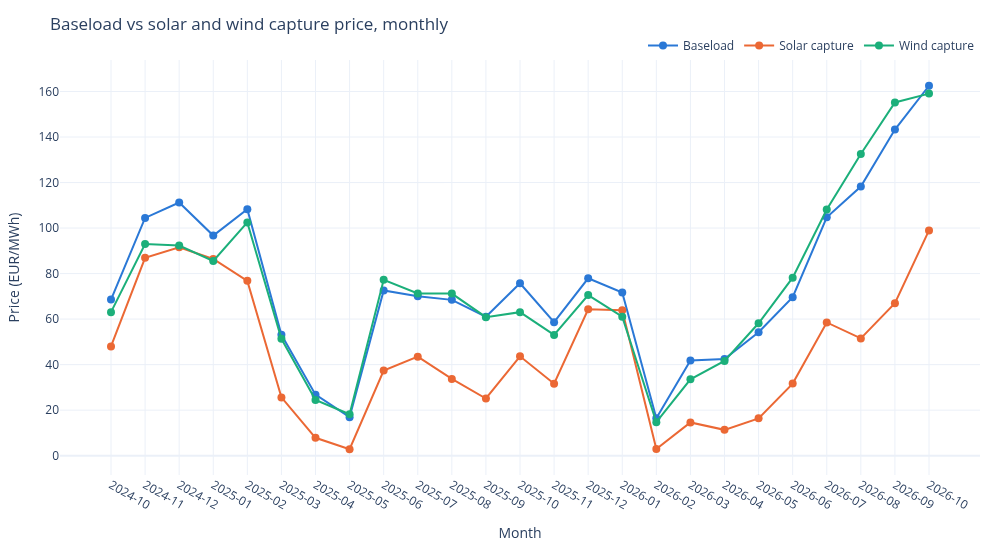

In [8]:
charts.fig_capture_prices(df).show(width=1000, height=550)

In [9]:
cap = t.capture_prices(df)
cap[["baseload", "solar_capture", "wind_capture", "solar_capture_rate", "solar_share"]]

,baseload,solar_capture,wind_capture,solar_capture_rate,solar_share
month,,,,,
2024-10,68.55,47.97,63.06,0.70,0.15
2024-11,104.43,86.92,92.94,0.83,0.13
2024-12,111.24,91.57,92.35,0.82,0.12
2025-01,96.69,86.40,85.52,0.89,0.11
2025-02,108.31,76.80,102.47,0.71,0.17
2025-03,53.09,25.60,51.33,0.48,0.16
2025-04,26.81,7.86,24.45,0.29,0.24
2025-05,16.93,2.81,18.18,0.17,0.29
2025-06,72.60,37.40,77.28,0.52,0.31


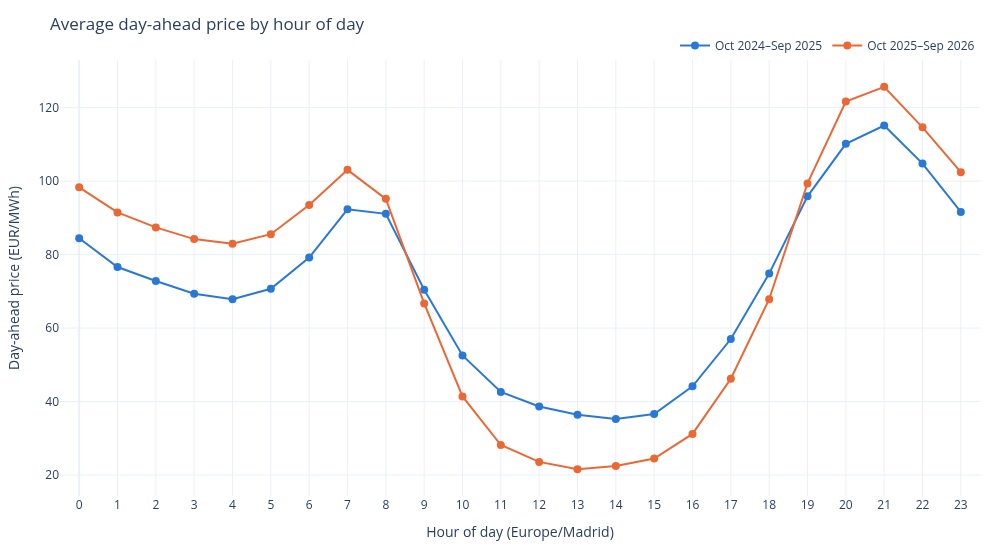

In [10]:
charts.fig_hourly_profile(df).show(width=1000, height=550)

In [11]:
md = t.midday_depression(df)
md

,midday,evening,spread,solar_share
month,,,,
2024-10,41.94,105.41,-63.47,0.15
2024-11,85.56,129.07,-43.51,0.13
2024-12,91.62,139.19,-47.57,0.12
2025-01,78.80,126.97,-48.17,0.11
2025-02,67.85,154.46,-86.61,0.17
2025-03,26.17,99.45,-73.28,0.16
2025-04,0.67,58.02,-57.36,0.24
2025-05,-3.63,42.12,-45.75,0.29
2025-06,19.52,113.24,-93.72,0.31


In [12]:
for name, col in w.items():
    print(f"{name}: solar share {col['solar_share']:.1%}, solar capture rate {col['solar_capture_rate']:.0%}, "
          f"midday (11-16h) {col['midday_11_16']:.1f} vs evening (19-22h) {col['evening_19_22']:.1f} EUR/MWh")
wm, wr = h["worst_capture_month"]
print(f"Worst month for solar: {wm}, capture rate {wr:.0%} of baseload")

Oct 2024–Sep 2025: solar share 21.5%, solar capture rate 56%, midday (11-16h) 38.9 vs evening (19-22h) 106.5 EUR/MWh
Oct 2025–Sep 2026: solar share 24.9%, solar capture rate 53%, midday (11-16h) 25.3 vs evening (19-22h) 115.3 EUR/MWh
Worst month for solar: 2025-05, capture rate 17% of baseload


Solar is sold mostly in the hours when solar itself pushes the price down, so its generation-weighted (capture) price sits far below baseload. That gap widened as solar's share of demand grew between the two windows. Midday prices fell while evening prices rose, which is the duck-curve spread that batteries and flexible demand earn from. Wind's capture price stays close to baseload because wind output is spread across the day.

**Caveats.** These are day-ahead prices only (no intraday or balancing markets, no capacity or ancillary revenues). REE real-time values are provisional, and the daily calibration fixes daily levels but not intra-day shape errors. The renewables share uses peninsular demand and ignores the Balearic and Canary systems.